# **New York City Airbnb**

Since 2008, guests and hosts have used Airbnb to expand on traveling possibilities and present more unique, personalized way of experiencing the world. This dataset describes the listing activity and metrics in NYC, NY for 2019.

## **1. Load data and copy dataframe**

In [14]:
import pandas as pd
# Load data and preprocessing the data
df=pd.read_csv('AB_NYC_2019.csv')
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,19-10-18,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,21-05-19,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,05-07-19,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,19-11-18,0.10,1,0


In [15]:
# copy the data (to make sure raw is untouched)
df_copy=df.copy()
df_copy.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,19-10-18,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,21-05-19,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,05-07-19,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,19-11-18,0.10,1,0


## **2.Preprocessing data step**

In [54]:
# 1. Chech the data type across columns
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              48895 non-null  object        
 1   name                            48879 non-null  object        
 2   host_id                         48895 non-null  object        
 3   host_name                       48874 non-null  object        
 4   neighbourhood_group             48895 non-null  object        
 5   neighbourhood                   48895 non-null  object        
 6   latitude                        48895 non-null  object        
 7   longitude                       48895 non-null  object        
 8   room_type                       48895 non-null  object        
 9   price                           48895 non-null  float64       
 10  minimum_nights                  48895 non-null  int64         
 11  nu

In [55]:
# 2. Check unique values
for col in df_copy.columns:
    print(f"Nilai unik data {col}")
    print(df_copy[col].unique())
    print("##"*50)

Nilai unik data id
['2539' '2595' '3647' ... '36485431' '36485609' '36487245']
####################################################################################################
Nilai unik data name
['Clean & quiet apt home by the park' 'Skylit Midtown Castle'
 'THE VILLAGE OF HARLEM....NEW YORK !' ...
 'Sunny Studio at Historical Neighborhood'
 '43rd St. Time Square-cozy single bed'
 "Trendy duplex in the very heart of Hell's Kitchen"]
####################################################################################################
Nilai unik data host_id
['2787' '2845' '4632' ... '274321313' '23492952' '68119814']
####################################################################################################
Nilai unik data host_name
['John' 'Jennifer' 'Elisabeth' ... 'Abayomi' 'Alberth' 'Ilgar & Aysel']
####################################################################################################
Nilai unik data neighbourhood_group
['Brooklyn' 'Manhattan' 'Queens' 'S

there's some price with zero values which should be investigate to validate wether it's free or NaN

In [57]:
print(f"Listing with zero price: {(df_copy['price']==0).sum()}")
print(f"Listing with zero min nights: {(df_copy['minimum_nights']==0).sum()}")

Listing with zero price: 11
Listing with zero min nights: 0


In [62]:
df_copy=df_copy[df_copy['price']>0]
print(f"Listing with zero price: {(df_copy['price']==0).sum()}")

Listing with zero price: 0


In [63]:
# 3. Change data types into a more suitable types
df_copy=df_copy.astype({
    'id':str,
    'host_id' : str,
    'latitude':str,
    'longitude':str,
    'price':float

})
df_copy['last_review']=pd.to_datetime(df['last_review'])

df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48884 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              48884 non-null  object        
 1   name                            48868 non-null  object        
 2   host_id                         48884 non-null  object        
 3   host_name                       48863 non-null  object        
 4   neighbourhood_group             48884 non-null  object        
 5   neighbourhood                   48884 non-null  object        
 6   latitude                        48884 non-null  object        
 7   longitude                       48884 non-null  object        
 8   room_type                       48884 non-null  object        
 9   price                           48884 non-null  float64       
 10  minimum_nights                  48884 non-null  int64         
 11  number_

C:\Users\Aulia Azzahra\AppData\Local\Temp\ipykernel_14108\789000473.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_copy['last_review']=pd.to_datetime(df['last_review'])


In [64]:
df_copy.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149.0,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225.0,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.9419,Private room,150.0,3,0,NaT,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89.0,1,270,2019-05-07,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80.0,10,9,2018-11-19,0.10,1,0


In [65]:
# 4. Check duplicates and nulls
print(f"Null data:\n {df_copy.isnull().sum()}")

Null data:
 id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10051
reviews_per_month                 10051
calculated_host_listings_count        0
availability_365                      0
dtype: int64


In [66]:
# Check Duplicates across the data and across all columns
print(f"Duplicate value: {df_copy.duplicated().sum()}")
print(f"Duplicate value accross all columns:\n{df_copy.apply(lambda col: col.duplicated().sum())}")

Duplicate value: 0
Duplicate value accross all columns:
id                                    0
name                                998
host_id                           11429
host_name                         37433
neighbourhood_group               48879
neighbourhood                     48663
latitude                          29838
longitude                         34169
room_type                         48881
price                             48211
minimum_nights                    48775
number_of_reviews                 48490
last_review                       47119
reviews_per_month                 47946
calculated_host_listings_count    48837
availability_365                  48518
dtype: int64


there's no duplicate value, the main id is the first column. so, multiple host id is still permissible because a host can have more than one listing

In [67]:
numerical_features=df_copy.select_dtypes(include=['number']).columns
numerical_features

Index(['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'],
      dtype='object')

In [68]:
# 5. Check the outlier
for col in numerical_features:
    q1=df_copy[col].quantile(0.25)
    q3=df_copy[col].quantile(0.75)
    iqr = q3-q1
    low=q1-1.5*iqr
    high=q3+1.5*iqr
    outliers=((df_copy[col]>high)|(df_copy[col]<low)).sum()
    total_count=df_copy[col].shape[0]
    print(f"Total outlier di {col}: {outliers}, {round((outliers/total_count)*100)}%")

Total outlier di price: 2972, 6%
Total outlier di minimum_nights: 6605, 14%
Total outlier di number_of_reviews: 6018, 12%
Total outlier di reviews_per_month: 1793, 4%
Total outlier di calculated_host_listings_count: 7073, 14%
Total outlier di availability_365: 0, 0%


the outliers will not get deleted because the context of the dataset

## **3. Data Visualization**

<Axes: title={'center': 'Minimum nights and Room type'}, xlabel='room_type', ylabel='minimum_nights'>

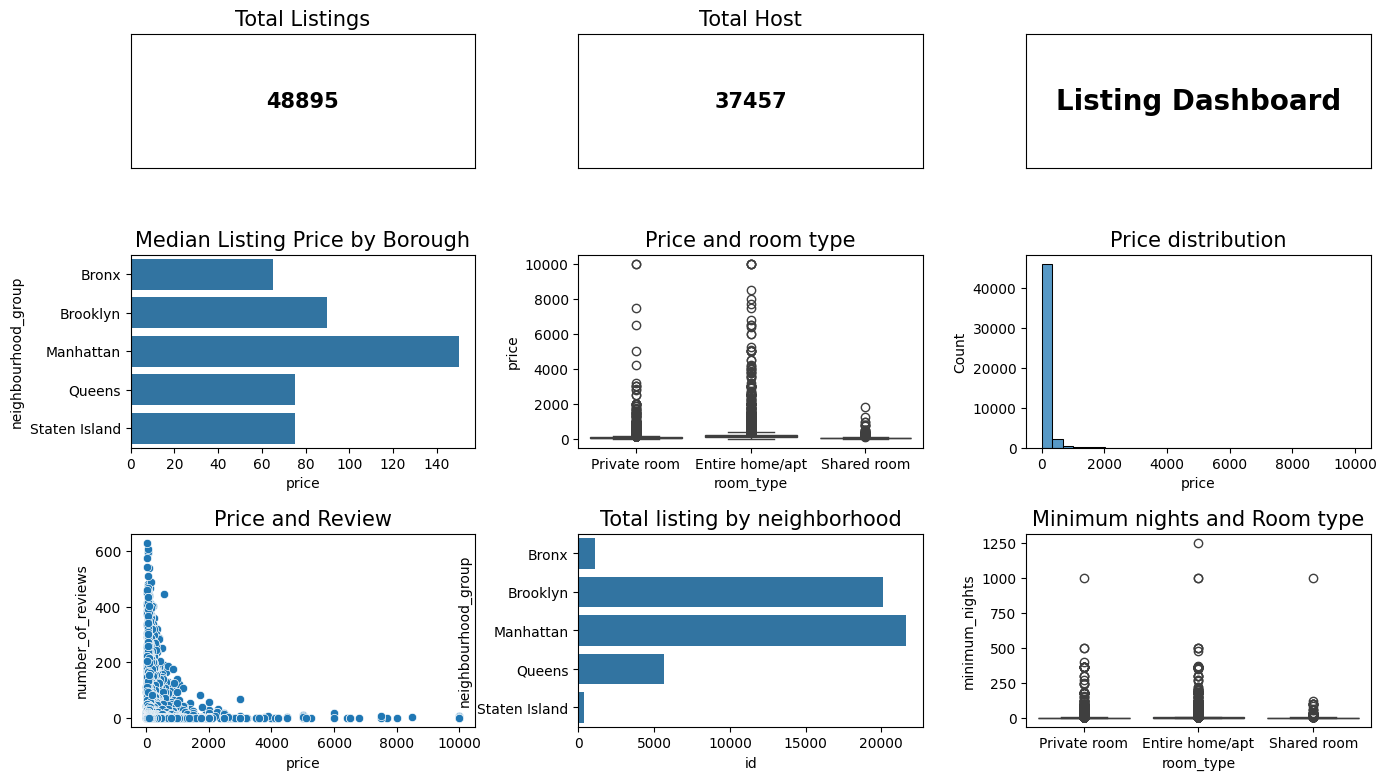

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns

fig = plt.figure(figsize=(16,9))
gs=fig.add_gridspec(
    3,3,
    height_ratios=[0.7,1,1],
    hspace=0.5,
    wspace=0.3
)

# KPIS
# Total listing di airbnb
ax_kpi1=fig.add_subplot(gs[0,0])
ax_kpi1.set_xticks([])
ax_kpi1.set_yticks([])
ax_kpi1.set_title("Total Listings",fontsize=15)
ax_kpi1.text(
    0.5,0.5,
    f'{df['id'].count()}',
    ha='center',
    va='center',
    fontsize=15,
    fontweight='bold',
    transform=ax_kpi1.transAxes
)

# total host
ax_kpi2=fig.add_subplot(gs[0,1])
ax_kpi2.set_xticks([])
ax_kpi2.set_yticks([])
ax_kpi2.set_title("Total Host",fontsize=15)
ax_kpi2.text(
    0.5,0.5,
    f'{df['host_id'].nunique()}',
    ha='center',
    va='center',
    fontsize=15,
    fontweight='bold',
    transform=ax_kpi2.transAxes
)

# title of dashboard
ax_tittledb = fig.add_subplot(gs[0,2])
ax_tittledb.set_yticks([])
ax_tittledb.set_xticks([])
ax_tittledb.text(
    0.5,0.5,
    "Listing Dashboard",
    ha='center',
    va='center',
    fontsize=20,
    fontweight='bold',
    transform=ax_tittledb.transAxes
)

# Bar chart -> top 10 harga tertinggi di neighborhood
highestNeighbor=df_copy.groupby('neighbourhood_group', as_index=False)['price'].median()
ax_highestNeighbor=fig.add_subplot(gs[1,0])
ax_highestNeighbor.set_title("Median Listing Price by Borough", fontsize=15)
sns.barplot(
    x='price',
    y='neighbourhood_group',
    data=highestNeighbor,
    ax=ax_highestNeighbor
)

# harga berdasarkan tipe kamar
ax_roomtype=fig.add_subplot(gs[1,1])
ax_roomtype.set_title("Price and room type", fontsize=15)
sns.boxplot(
    x='room_type',
    y='price',
    data=df_copy,
    ax=ax_roomtype
)

# persebaran range data harga
ax_pricedist=fig.add_subplot(gs[1,2])
ax_pricedist.set_title("Price distribution",fontsize=15)
sns.histplot(
    data=df_copy,
    x='price',
    bins=30
)

# scatterplot relationship harga tinggi review banyak
ax_pricevsreview=fig.add_subplot(gs[2,0])
ax_pricevsreview.set_title("Price and Review",fontsize=15)
sns.scatterplot(
    data=df_copy,
    x='price',
    y='number_of_reviews',
    ax=ax_pricevsreview
)

# barchart -> neighborhood the highest total of listing
listingneighbor=df.groupby('neighbourhood_group',as_index=False)['id'].count()
ax_listingneighbor = fig.add_subplot(gs[2,1])
ax_listingneighbor.set_title("Total listing by neighborhood", fontsize=15)
sns.barplot(
    data=listingneighbor,
    x='id',
    y='neighbourhood_group',
    ax=ax_listingneighbor
)

# minimum nights with room typw
ax_roomnights = fig.add_subplot(gs[2,2])
ax_roomnights.set_title("Minimum nights and Room type", fontsize=15)
sns.boxplot(
    data=df_copy,
    x='room_type',
    y='minimum_nights',
    ax=ax_roomnights
)


## **Calculation for insights power point**

In [93]:
print(df_copy[numerical_features].corr())

                                   price  minimum_nights  number_of_reviews  \
price                           1.000000        0.042805          -0.047926   
minimum_nights                  0.042805        1.000000          -0.080080   
number_of_reviews              -0.047926       -0.080080           1.000000   
reviews_per_month              -0.030575       -0.121644           0.549763   
calculated_host_listings_count  0.057462        0.127962          -0.072385   
availability_365                0.081847        0.144275           0.171975   

                                reviews_per_month  \
price                                   -0.030575   
minimum_nights                          -0.121644   
number_of_reviews                        0.549763   
reviews_per_month                        1.000000   
calculated_host_listings_count          -0.009431   
availability_365                         0.185730   

                                calculated_host_listings_count  \
price   

In [77]:
print(highestNeighbor)

  neighbourhood_group  price
0               Bronx   65.0
1            Brooklyn   90.0
2           Manhattan  150.0
3              Queens   75.0
4       Staten Island   75.0


In [84]:
df_copy.groupby('room_type')['price'].max()

room_type
Entire home/apt    10000.0
Private room       10000.0
Shared room         1800.0
Name: price, dtype: float64

In [82]:
df_copy.groupby('room_type')['id'].count()


room_type
Entire home/apt    25407
Private room       22319
Shared room         1158
Name: id, dtype: int64

In [86]:
((df_copy['price']>0)&(df_copy['price']<=333)).sum()

np.int64(45907)

In [91]:
df_copy.groupby('neighbourhood_group')['id'].count()


neighbourhood_group
Bronx             1090
Brooklyn         20095
Manhattan        21660
Queens            5666
Staten Island      373
Name: id, dtype: int64

In [96]:
print(((df_copy['room_type']=='Entire home/apt')&(df_copy['minimum_nights']<750)).sum())

25404


In [97]:
print(((df_copy['room_type']=='Entire home/apt')&(df_copy['minimum_nights']>750)).sum())

3


In [99]:
print(((df_copy['room_type']=='Private room')&(df_copy['minimum_nights']<750)).sum())

22318


In [100]:
print(((df_copy['room_type']=='Shared room')&(df_copy['minimum_nights']<750)).sum())

1157


In [102]:
print(((df_copy['neighbourhood_group']=='Manhattan')&(df_copy['room_type']=='Entire home/apt')).sum())
print(((df_copy['neighbourhood_group']=='Manhattan')&(df_copy['room_type']=='Private room')).sum())
print(((df_copy['neighbourhood_group']=='Manhattan')&(df_copy['room_type']=='Shared room')).sum())

13198
7982
480


In [103]:
df_copy.groupby('room_type')['minimum_nights'].agg(
    ['count', 'median', 'mean', 'min', 'max']
)

,count,median,mean,min,max
room_type,,,,,
Entire home/apt,25407,3.0,8.507262,1,1250
Private room,22319,2.0,5.379004,1,999
Shared room,1158,1.0,6.434370,1,999


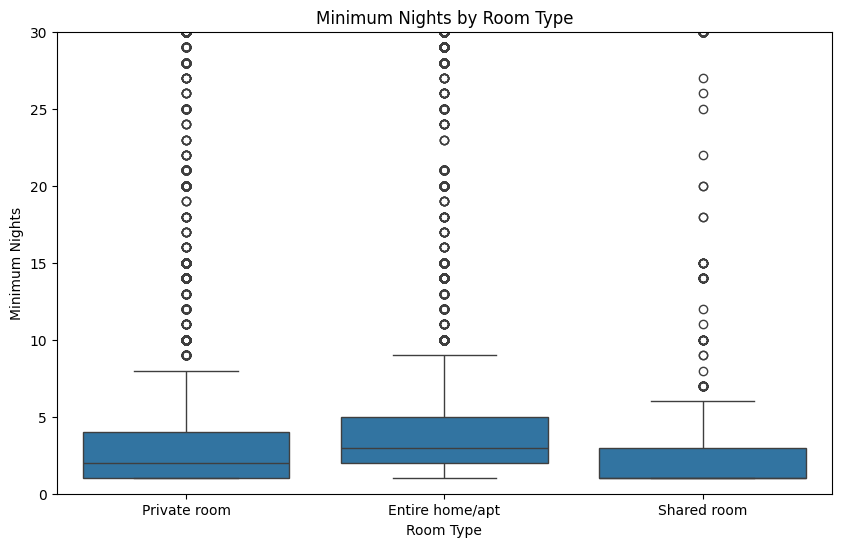

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_copy,
    x='room_type',
    y='minimum_nights'
)

plt.title('Minimum Nights by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Minimum Nights')
plt.ylim(0, 30)

plt.show()